# Livrable 3 · Analyse technique du portefeuille

Toutes les valeurs proviennent de l'entrepôt (`data/warehouse/boreal.duckdb`), schéma `marts`, construit par `make run`.
Les indicateurs sont définis une seule fois dans `analyse/indicateurs.py`, partagé avec le dashboard.

| Indicateur | Définition |
|---|---|
| Années-police | Durée de couverture en années (jours couverts / 365), base de toute fréquence |
| Fréquence | Sinistres avec suite (ouverts ou clôturés) / années-police |
| Coût moyen | Charge / sinistres avec suite |
| Charge | Règlements payés + réserve restante des dossiers ouverts |
| Prime moyenne | Primes acquises / années-police |
| S/P | Charge / primes acquises (= fréquence × coût moyen / prime moyenne) |
| Taux de résiliation | Résiliations / années-police (taux annuel) |

Les sinistres sont rattachés à leur **année de survenance**. Les sinistres rejetés ou sans suite sont comptés à part : ils ne coûtent rien mais occupent la gestion.

In [1]:
import sys, pathlib
RACINE = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from analyse.indicateurs import (lire, indicateurs, decomposer_sp, contributions_segments,
                                 ic_poisson, ic_bootstrap_ratio, test_taux_poisson)

FIGURES = RACINE / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"axes.titlesize": 10})

mt = lire("SELECT * FROM marts.mart_technique ORDER BY ALL")             # mesures additives agrégées
ca = lire("SELECT * FROM marts.mart_contrat_annee ORDER BY exposition_id")         # grain contrat × année
si = lire("SELECT * FROM marts.mart_sinistres ORDER BY sinistre_id")             # grain sinistre
avec_suite = si[~si["est_sans_suite"]]

def tableau(axes, donnees=mt):
    t = indicateurs(donnees, axes)
    return pd.DataFrame({
        **{a: t[a] for a in axes},
        "années-police": t["annees_police"].round(0).astype(int),
        "sinistres": t["nb_sinistres"].astype(int),
        "sans suite": t["nb_sinistres_sans_suite"].astype(int),
        "fréquence %": (100 * t["frequence"]).round(2),
        "coût moyen €": t["cout_moyen"].round(0),
        "prime moy. €": t["prime_moyenne"].round(0),
        "S/P %": (100 * t["sp"]).round(1),
        "S/P hors atypique %": (100 * t["sp_hors_atypique"]).round(1),
        "résiliation %": (100 * t["taux_resiliation"]).round(1),
    })

print(f"{len(ca):,} lignes contrat × année, {len(si):,} sinistres valides, "
      f"{ca['annees_police'].sum():,.1f} années-police, {ca['prime_acquise'].sum():,.0f} € de primes acquises")

65,109 lignes contrat × année, 2,783 sinistres valides, 45,215.1 années-police, 20,001,523 € de primes acquises


## 1. Indicateurs techniques

### Vue d'ensemble par produit

In [2]:
tableau(["produit"])

,produit,années-police,sinistres,sans suite,fréquence %,coût moyen €,prime moy. €,S/P %,S/P hors atypique %,résiliation %
0,AUTO,23238,1019,609,4.38,7544.0,589.0,56.1,38.0,14.7
1,HABITATION,21977,926,229,4.21,4343.0,287.0,63.8,63.8,14.4


**Lecture.** L'habitation est le produit le moins rentable : son S/P (63,8 %) dépasse celui de l'auto hors sinistre atypique (38,0 %), alors que sa fréquence est voisine. **Action : la revue tarifaire doit commencer par l'habitation**, dont la prime moyenne (287 €) couvre mal le coût moyen.

L'écart entre le S/P auto (56,1 %) et le S/P auto hors atypique (38,0 %) est dû à un seul dossier (sinistre 1129, 2,48 M€). Il est traité au § 3.

### Par zone de risque

In [3]:
tableau(["produit", "zone_risque"])

,produit,zone_risque,années-police,sinistres,sans suite,fréquence %,coût moyen €,prime moy. €,S/P %,S/P hors atypique %,résiliation %
0,AUTO,1,4462,171,108,3.83,6050.0,526.0,44.1,44.1,14.5
1,AUTO,2,5886,235,142,3.99,5240.0,563.0,37.2,37.2,14.6
2,AUTO,3,5747,263,149,4.58,5416.0,596.0,41.6,41.6,15.1
3,AUTO,4,4698,213,140,4.53,16051.0,636.0,114.4,31.5,14.7
4,AUTO,5,2445,137,70,5.60,4217.0,665.0,35.6,35.6,13.9
5,HABITATION,1,4521,134,30,2.96,4140.0,251.0,48.9,48.9,14.0
6,HABITATION,2,5397,219,58,4.06,4257.0,273.0,63.2,63.2,14.4
7,HABITATION,3,5554,235,58,4.23,4787.0,293.0,69.0,69.0,14.6
8,HABITATION,4,4218,206,49,4.88,3445.0,310.0,54.2,54.2,14.7
9,HABITATION,5,2287,132,34,5.77,5300.0,331.0,92.5,92.5,14.5


**Lecture.** En habitation, la fréquence double de la zone 1 (2,96 %) à la zone 5 (5,77 %), mais la prime moyenne n'augmente que de 32 % (251 € → 331 €). Le S/P de la zone 5 atteint donc 92,5 %. **Action : relever le tarif habitation des zones 4 et 5**, dont la prime ne suit pas le risque (test au § 3).

En auto, le S/P de 114 % en zone 4 vient du seul sinistre atypique. Hors ce dossier, il est de 31,5 %, le plus bas des zones.

### Par formule

In [4]:
tableau(["produit", "formule"])

,produit,formule,années-police,sinistres,sans suite,fréquence %,coût moyen €,prime moy. €,S/P %,S/P hors atypique %,résiliation %
0,AUTO,CONFORT,9301,566,114,6.09,8702.0,589.0,90.0,44.7,13.9
1,AUTO,ESSENTIELLE,7853,133,396,1.69,8940.0,496.0,30.5,30.5,16.9
2,AUTO,PREMIUM,6084,320,99,5.26,4914.0,711.0,36.3,36.3,12.9
3,HABITATION,CONFORT,8747,383,63,4.38,4081.0,287.0,62.4,62.4,13.4
4,HABITATION,ESSENTIELLE,7374,270,119,3.66,4920.0,239.0,75.5,75.5,17.1
5,HABITATION,PREMIUM,5856,273,47,4.66,4140.0,348.0,55.4,55.4,12.6


**Lecture.** La formule Essentielle cumule deux signaux.
- En auto, sa fréquence n'est que de 1,69 %, mais 396 déclarations restent sans suite contre 133 sinistres indemnisés (tableau des sans-suite plus bas).
- En habitation, elle a le S/P le plus élevé (75,5 %) et la plus forte résiliation (17,1 %).

**Action : revoir la prime de l'Essentielle habitation et mieux expliquer ses garanties** aux assurés auto pour réduire les déclarations non couvertes.

### Par canal de distribution

In [5]:
tableau(["produit", "canal_distribution"])

,produit,canal_distribution,années-police,sinistres,sans suite,fréquence %,coût moyen €,prime moy. €,S/P %,S/P hors atypique %,résiliation %
0,AUTO,AGENT,9804,430,244,4.39,11273.0,590.0,83.8,41.0,12.3
1,AUTO,COURTIER,4736,207,116,4.37,4808.0,591.0,35.6,35.6,12.0
2,AUTO,WEB,8698,382,249,4.39,4828.0,588.0,36.0,36.0,18.7
3,HABITATION,AGENT,9068,383,91,4.22,4961.0,287.0,73.1,73.1,11.7
4,HABITATION,COURTIER,4591,191,52,4.16,3570.0,289.0,51.5,51.5,13.0
5,HABITATION,WEB,8318,352,86,4.23,4089.0,286.0,60.4,60.4,18.2


**Lecture.** Le canal ne change ni la fréquence (4,2 à 4,4 % partout) ni la prime. Il change la fidélité : les contrats vendus sur le Web se résilient à 18,7 % (auto) et 18,2 % (habitation) par an, contre 12 % environ en agence ou en courtage. **Action : cibler un plan de fidélisation sur les souscripteurs Web**, par exemple un contact à la première échéance.

Le S/P auto élevé de l'agence (83,8 %) vient du sinistre atypique, souscrit en agence. Hors ce dossier, il est de 41,0 %.

### Par tranche d'âge (âge à la date d'extraction)

In [6]:
tableau(["produit", "tranche_age"])

,produit,tranche_age,années-police,sinistres,sans suite,fréquence %,coût moyen €,prime moy. €,S/P %,S/P hors atypique %,résiliation %
0,AUTO,18-25,1984,147,107,7.41,4543.0,825.0,40.8,40.8,16.1
1,AUTO,26-35,3387,156,67,4.61,3693.0,560.0,30.4,30.4,14.6
2,AUTO,36-50,8509,319,201,3.75,13650.0,558.0,91.6,39.5,14.5
3,AUTO,51-65,6666,279,153,4.19,5226.0,564.0,38.8,38.8,14.5
4,AUTO,66+,2267,96,73,4.24,4866.0,615.0,33.5,33.5,14.3
5,AUTO,Inconnu,426,22,8,5.17,7433.0,603.0,63.7,63.7,15.0
6,HABITATION,18-25,1871,79,18,4.22,2986.0,286.0,44.2,44.2,14.7
7,HABITATION,26-35,3266,116,28,3.55,4793.0,285.0,59.7,59.7,14.3
8,HABITATION,36-50,8132,355,84,4.37,4529.0,287.0,69.0,69.0,13.9
9,HABITATION,51-65,6250,270,66,4.32,4236.0,288.0,63.6,63.6,14.8


**Lecture.** Les 18-25 ans ont la fréquence auto la plus forte (7,41 %), mais leur surprime (825 € contre environ 560 €) maintient leur S/P à 40,8 %, dans la moyenne. Le tarif jeune conducteur est donc adapté. **Action : ne pas modifier le tarif auto par âge, et surveiller l'habitation des 36-50 ans** (S/P de 69,0 %, sur la plus forte exposition).

La tranche « Inconnu » regroupe les dates de naissance absentes ou corrigées au livrable 2. Elle pèse moins de 2 % de l'exposition.

### Payé, réserves et sinistres sans suite

La charge totale se compose des règlements déjà payés et de la réserve restante des dossiers encore ouverts. Les sinistres rejetés ou sans suite ne coûtent rien mais doivent être comptés à part.

In [7]:
t = indicateurs(mt, ["annee"])
pd.DataFrame({
    "année": t["annee"],
    "déclarés": t["nb_sinistres_declares"].astype(int),
    "avec suite": t["nb_sinistres"].astype(int),
    "sans suite": t["nb_sinistres_sans_suite"].astype(int),
    "% sans suite": (100 * t["part_sans_suite"]).round(1),
    "payé €": t["montant_paye"].round(0),
    "réserve restante €": t["reserve_restante"].round(0),
    "% réserve dans la charge": (100 * t["part_reserve"]).round(1),
})

,année,déclarés,avec suite,sans suite,% sans suite,payé €,réserve restante €,% réserve dans la charge
0,2020,124,95,29,23.4,481796.0,0.0,0.0
1,2021,334,224,110,32.9,939905.0,0.0,0.0
2,2022,524,377,147,28.1,1859627.0,0.0,0.0
3,2023,615,442,173,28.1,4307540.0,0.0,0.0
4,2024,788,533,255,32.4,2723660.0,41430.0,1.5
5,2025,398,274,124,31.2,864132.0,490266.0,36.2


**Lecture.**
- **Les réserves pèsent 36 % de la charge 2025** et environ 2 % de celle de 2024. Les chiffres de ces deux années sont provisoires.
- **30 % des déclarations restent sans suite** (838 sur 2 783).

**Action : présenter 2025 comme provisoire dans tout reporting**, et suivre le taux de sans-suite comme indicateur de coût de gestion.

In [8]:
pivot = (si.groupby(["produit", "formule", "garantie"])["est_sans_suite"].agg(["count", "mean"])
           .rename(columns={"count": "déclarés", "mean": "% sans suite"}))
pivot["% sans suite"] = (100 * pivot["% sans suite"]).round(0)
pivot.unstack("formule")

déclarés                     % sans suite              \
formule                CONFORT ESSENTIELLE PREMIUM      CONFORT ESSENTIELLE   
produit    garantie                                                           
AUTO       BRIS_GLACE      131         100     101         64.0       100.0   
           COLLISION       295         237     156          7.0       100.0   
           RC              189         134     118          3.0         1.0   
           VOL              65          58      44          5.0       100.0   
HABITATION DEGAT_EAUX      219         197     177         16.0        17.0   
           INCENDIE         41          38      29          0.0         0.0   
           TEMPETE          93          79      62         24.0       100.0   
           VOL              93          75      52          6.0         9.0   

                               
formule               PREMIUM  
produit    garantie            
AUTO       BRIS_GLACE    74.0  
           COLLISION      8.0  
           RC             5.0  
           VOL           11.0  
HABITATION DEGAT_EAUX    20.0  
           INCENDIE       0.0  
           TEMPETE       18.0  
           VOL            2.0

**Lecture.** La formule Essentielle ne couvre pas la collision, le bris de glace et le vol en auto, ni la tempête en habitation : 100 % de ces déclarations sont rejetées (474 dossiers). En Confort et Premium, le bris de glace reste sans suite dans 64 à 74 % des cas, sans doute sous la franchise. **Action : rappeler les exclusions de garantie dans les documents de l'Essentielle et à la déclaration**, pour éviter des dossiers ouverts pour rien.

## 2. Décomposition de l'évolution du S/P

Comme **S/P = fréquence × coût moyen / prime moyenne**, on a exactement Δln S/P = Δln F + Δln C − Δln P. Chaque effet est converti en points de S/P par la méthode LMDI : la somme des effets égale exactement la variation observée.

Le **volume** d'années-police multiplie à la fois la charge et les primes. Son effet sur le S/P est donc nul par construction. On le chiffre sur la charge pour montrer qu'il explique la croissance des montants, pas celle du ratio.

**Années incomplètes :**
- **2020 :** le portefeuille démarre le 01/01/2020, l'exposition est faible (1 857 années-police).
- **2025 :** seuls six mois sont observés, et 36 % de la charge est encore en réserve.
- **2024 :** quelques dossiers restent ouverts.
- **Sinistres tardifs :** les sinistres survenus mais pas encore déclarés au 30/06/2025 ne sont pas connus. Les S/P 2024 et 2025 sont donc des minima.

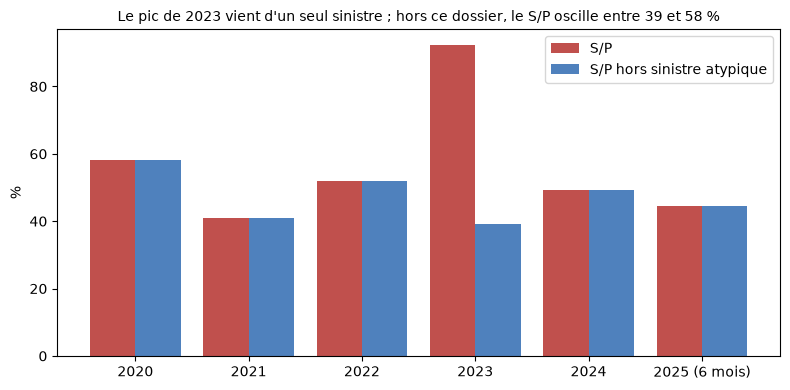

In [9]:
annuel = indicateurs(mt, ["annee"])
fig, ax = plt.subplots(figsize=(8, 4))
x = annuel["annee"]
ax.bar(x - 0.2, 100 * annuel["sp"], width=0.4, label="S/P", color="#c0504d")
ax.bar(x + 0.2, 100 * annuel["sp_hors_atypique"], width=0.4, label="S/P hors sinistre atypique", color="#4f81bd")
ax.set_ylabel("%"); ax.set_title("Le pic de 2023 vient d'un seul sinistre ; hors ce dossier, le S/P oscille entre 39 et 58 %")
ax.legend(); ax.set_xticks(x); ax.set_xticklabels([f"{a}{' (6 mois)' if a == 2025 else ''}" for a in x])
fig.tight_layout(); fig.savefig(FIGURES / "l3_sp_annuel.png", dpi=150)

In [10]:
def presenter(d):
    return pd.DataFrame({
        "année": d["annee"],
        "S/P N-1 %": (100 * d["sp_precedent"]).round(1),
        "S/P N %": (100 * d["sp"]).round(1),
        "variation (pts)": (100 * d["variation_sp"]).round(1),
        "effet fréquence": (100 * d["effet_frequence"]).round(1),
        "effet coût moyen": (100 * d["effet_cout_moyen"]).round(1),
        "effet prime moyenne": (100 * d["effet_prime_moyenne"]).round(1),
        "effet volume": (100 * d["effet_volume"]).round(1),
        "effet volume sur la charge €": d["effet_volume_sur_charge"].round(0),
    })

print("Toute la charge"); display(presenter(decomposer_sp(annuel)))
print("Hors sinistre atypique"); display(presenter(decomposer_sp(annuel, "charge_hors_atypique")))

Toute la charge


,année,S/P N-1 %,S/P N %,variation (pts),effet fréquence,effet coût moyen,effet prime moyenne,effet volume,effet volume sur la charge €
0,2021,58.3,41.0,-17.3,-8.0,-9.3,0.0,0.0,699806.0
1,2022,41.0,52.0,11.0,3.3,7.5,0.2,0.0,605197.0
2,2023,52.0,92.4,40.4,-7.6,47.8,0.2,0.0,780245.0
3,2024,92.4,49.4,-43.0,0.3,-43.3,0.0,0.0,638644.0
4,2025,49.4,44.5,-4.8,-2.6,-2.3,0.0,0.0,-1205762.0


Hors sinistre atypique


,année,S/P N-1 %,S/P N %,variation (pts),effet fréquence,effet coût moyen,effet prime moyenne,effet volume,effet volume sur la charge €
0,2021,58.3,41.0,-17.3,-8.0,-9.3,0.0,0.0,699806.0
1,2022,41.0,52.0,11.0,3.3,7.5,0.2,0.0,605197.0
2,2023,52.0,39.3,-12.7,-4.9,-7.9,0.1,0.0,494127.0
3,2024,39.3,49.4,10.1,0.2,9.9,0.0,0.0,415978.0
4,2025,49.4,44.5,-4.8,-2.6,-2.3,0.0,0.0,-1205762.0


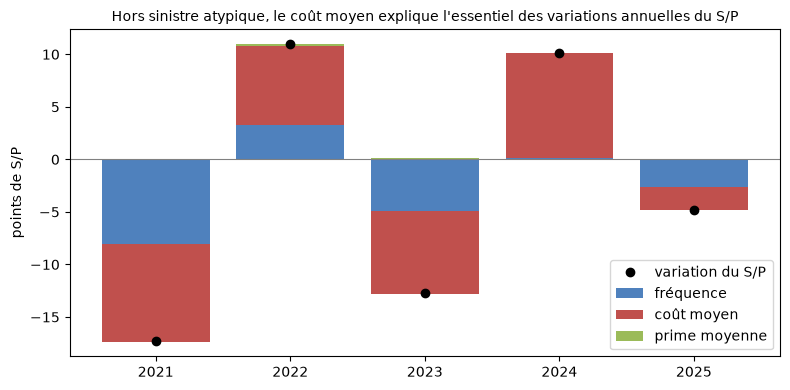

In [11]:
d = decomposer_sp(annuel, "charge_hors_atypique")
fig, ax = plt.subplots(figsize=(8, 4))
bas = np.zeros(len(d))
for col, couleur, nom in [("effet_frequence", "#4f81bd", "fréquence"), ("effet_cout_moyen", "#c0504d", "coût moyen"),
                          ("effet_prime_moyenne", "#9bbb59", "prime moyenne")]:
    v = 100 * d[col].to_numpy()
    ax.bar(d["annee"], v, bottom=np.where(v >= 0, np.maximum(bas, 0), np.minimum(bas, 0)), color=couleur, label=nom)
    bas += v
ax.plot(d["annee"], 100 * d["variation_sp"], "ko", label="variation du S/P")
ax.axhline(0, color="grey", lw=0.8); ax.set_ylabel("points de S/P")
ax.set_title("Hors sinistre atypique, le coût moyen explique l'essentiel des variations annuelles du S/P")
ax.legend(); fig.tight_layout(); fig.savefig(FIGURES / "l3_decomposition_sp.png", dpi=150)

**Lecture.**
- **La prime moyenne n'a pas bougé** de 2020 à 2025 (445 € → 441 €), son effet ne dépasse pas 0,2 point par an. Aucune hausse tarifaire n'a compensé l'inflation des coûts.
- **La fréquence est stable** (4,0 à 4,7 % hors 2020). Hors sinistre atypique, son effet reste inférieur à 5 points par an, sauf en 2021 (−8,0 points) où la fréquence baisse depuis une année 2020 peu exposée.
- **Le coût moyen fait le S/P.** Toute la charge : +47,8 points en 2023 (sinistre 1129), puis −43,3 en 2024. Hors ce dossier : −7,9 en 2023 et +9,9 en 2024.
- **Le volume** a fait croître la charge de 0,6 à 0,8 M€ par an de 2021 à 2024, sans effet sur le ratio. 2025, observée sur six mois, n'est pas comparable.

**Action :**
- Piloter le S/P par le coût moyen : suivi des dossiers graves, recours, expertise.
- Réviser les primes, figées depuis 2020.

### Segments qui contribuent le plus (produit × zone, hors sinistre atypique)

In [12]:
lignes = []
for annee in [2021, 2022, 2023, 2024, 2025]:
    c = contributions_segments(mt, ["produit", "zone_risque"], annee, "charge_hors_atypique")
    for _, r in pd.concat([c.head(2), c.tail(2)]).iterrows():
        lignes.append({"année": annee, "segment": f"{r['produit']} zone {int(r['zone_risque'])}",
                       "contribution (pts de S/P)": round(100 * r["contribution_variation"], 1),
                       "sens": "dégradation" if r["contribution_variation"] > 0 else "amélioration"})
pd.DataFrame(lignes)

,année,segment,contribution (pts de S/P),sens
0,2021,AUTO zone 1,-12.3,amélioration
1,2021,AUTO zone 3,-7.8,amélioration
2,2021,HABITATION zone 1,3.2,dégradation
3,2021,AUTO zone 2,7.4,dégradation
4,2022,HABITATION zone 1,-3.7,amélioration
5,2022,HABITATION zone 4,-3.1,amélioration
6,2022,HABITATION zone 3,3.8,dégradation
7,2022,AUTO zone 1,8.3,dégradation
8,2023,AUTO zone 1,-7.3,amélioration
9,2023,AUTO zone 2,-5.2,amélioration


**Lecture.** Les segments qui dégradent le S/P changent chaque année, au gré des gros sinistres :
- **2022 :** auto zone 1 (+8,3 points) ;
- **2024 :** auto zone 3 (+3,6 points) et habitation zone 3 (+2,3 points) ;
- **2025 :** habitation zone 5 (+8,6 points), à cause d'un incendie encore ouvert de 110 671 € (sinistre 2526).

L'habitation zone 5 est le seul segment à la fois structurellement cher (§ 1) et contributeur récent. **Action : le placer en tête de la révision tarifaire et de la prévention (incendie).** Les autres variations relèvent de la volatilité des sinistres graves.

## 3. Rigueur statistique

### Intervalles de confiance à 95 %

| Indicateur | Méthode | Pourquoi |
|---|---|---|
| Fréquence, résiliation | Intervalle exact de Poisson (Garwood) | Nombre d'événements rapporté à une exposition |
| Coût moyen | Bootstrap percentile sur les sinistres (5 000 tirages) | Distribution très asymétrique : l'approximation normale serait trompeuse |
| S/P, prime moyenne | Bootstrap percentile sur les contrats (5 000 tirages) | Ratio de sommes, avec plusieurs années par contrat |

In [13]:
par_contrat = ca.groupby(["contrat_id", "produit"], as_index=False)[
    ["annees_police", "prime_acquise", "charge", "charge_hors_atypique", "nb_sinistres", "nb_resiliations"]].sum()

lignes = []
for produit in ["Ensemble", "AUTO", "HABITATION"]:
    p = par_contrat if produit == "Ensemble" else par_contrat[par_contrat["produit"] == produit]
    s = avec_suite if produit == "Ensemble" else avec_suite[avec_suite["produit"] == produit]
    ap = p["annees_police"].sum()
    mesures = {
        "fréquence %": (p["nb_sinistres"].sum() / ap, ic_poisson(p["nb_sinistres"].sum(), ap), 100),
        "coût moyen €": (s["charge_totale"].mean(), ic_bootstrap_ratio(s["charge_totale"], np.ones(len(s))), 1),
        "prime moyenne €": (p["prime_acquise"].sum() / ap, ic_bootstrap_ratio(p["prime_acquise"], p["annees_police"]), 1),
        "S/P %": (p["charge"].sum() / p["prime_acquise"].sum(), ic_bootstrap_ratio(p["charge"], p["prime_acquise"]), 100),
        "S/P hors atypique %": (p["charge_hors_atypique"].sum() / p["prime_acquise"].sum(),
                                ic_bootstrap_ratio(p["charge_hors_atypique"], p["prime_acquise"]), 100),
        "résiliation %": (p["nb_resiliations"].sum() / ap, ic_poisson(p["nb_resiliations"].sum(), ap), 100),
    }
    for nom, (valeur, (bas, haut), echelle) in mesures.items():
        lignes.append({"produit": produit, "indicateur": nom, "valeur": round(echelle * valeur, 2),
                       "IC 95 % bas": round(echelle * bas, 2), "IC 95 % haut": round(echelle * haut, 2)})
ic = pd.DataFrame(lignes)
ic.pivot(index="indicateur", columns="produit", values=["valeur", "IC 95 % bas", "IC 95 % haut"]).round(2)

valeur                     IC 95 % bas           \
produit                 AUTO Ensemble HABITATION        AUTO Ensemble   
indicateur                                                              
S/P %                  56.12    58.54      63.78       34.04    42.66   
S/P hors atypique %    38.05    46.16      63.78       32.83    41.60   
coût moyen €         7543.58  6019.72    4342.81     4625.23  4418.10   
fréquence %             4.38     4.30       4.21        4.12     4.11   
prime moyenne €       589.37   442.36     286.92      585.53   438.93   
résiliation %          14.65    14.54      14.42       14.16    14.19   

                               IC 95 % haut                      
produit             HABITATION         AUTO Ensemble HABITATION  
indicateur                                                       
S/P %                    55.21        95.82    86.05      73.66  
S/P hors atypique %      55.21        44.21    51.21      73.66  
coût moyen €           3804.46     12991.57  8845.51    4943.58  
fréquence %               3.95         4.66     4.50       4.49  
prime moyenne €         285.28       593.25   445.80     288.54  
résiliation %            13.92        15.15    14.90      14.93

**Lecture.**
- **Fréquence, prime moyenne et résiliation sont mesurées précisément**, à quelques dixièmes de point près.
- **Le S/P auto est très incertain** (34 % à 96 %) à cause d'un seul dossier. Hors ce dossier, l'intervalle se resserre à 33-44 %.
- **Le S/P habitation (55 % à 74 %) est significativement au-dessus** du S/P auto hors atypique, puisque les deux intervalles ne se chevauchent pas.

**Action : comparer les produits sur le S/P hors sinistres graves**, et traiter les sinistres graves à part (provision, réassurance).

### Test 1 : la fréquence habitation est-elle plus élevée en zone 5 qu'en zone 1 ?

Le nombre de sinistres sur une exposition suit un processus de Poisson. On compare deux taux avec le **test E de Krishnamoorthy et Thomson** (`scipy.stats.poisson_means_test`), adapté aux expositions inégales.
- H0 : les deux zones ont la même fréquence.
- Test bilatéral, au seuil de 5 %.

In [14]:
h = indicateurs(mt[mt["produit"] == "HABITATION"], ["zone_risque"]).set_index("zone_risque")
r = test_taux_poisson(h.loc[5, "nb_sinistres"], h.loc[5, "annees_police"], h.loc[1, "nb_sinistres"], h.loc[1, "annees_police"])
print(f"Zone 5 : {100*r['taux_1']:.2f} %  |  Zone 1 : {100*r['taux_2']:.2f} %  |  rapport {r['rapport']:.2f}  |  p = {r['p_valeur']:.1e}")

Zone 5 : 5.77 %  |  Zone 1 : 2.96 %  |  rapport 1.95  |  p = 1.6e-06


**Conclusion.** La fréquence habitation est 1,95 fois plus élevée en zone 5 qu'en zone 1 (p = 2·10⁻⁶). L'écart n'est pas dû au hasard. Il justifie un tarif zoné plus différencié que l'écart de prime actuel (+32 %).

### Test 2 : les sinistres auto coûtent-ils plus cher quand le contrat a été vendu en agence plutôt que sur le Web ?

Les coûts sont très asymétriques : la moyenne est tirée par quelques dossiers et la normalité est exclue. On utilise donc le **test de Mann-Whitney**, qui compare les distributions par les rangs sans hypothèse de normalité.
- H0 : un sinistre tiré de l'un des deux canaux a autant de chances d'être le plus cher.
- Test bilatéral, au seuil de 5 %.

In [15]:
auto = avec_suite[avec_suite["produit"] == "AUTO"]
agent, web = auto.loc[auto["canal_distribution"] == "AGENT", "charge_totale"], auto.loc[auto["canal_distribution"] == "WEB", "charge_totale"]
mw = stats.mannwhitneyu(agent, web, alternative="two-sided")
print(f"Agence : n={len(agent)}, moyenne {agent.mean():,.0f} €, médiane {agent.median():,.0f} €")
print(f"Web    : n={len(web)}, moyenne {web.mean():,.0f} €, médiane {web.median():,.0f} €")
print(f"Mann-Whitney : U = {mw.statistic:,.0f}, p = {mw.pvalue:.2f}")

Agence : n=430, moyenne 11,273 €, médiane 2,278 €
Web    : n=382, moyenne 4,828 €, médiane 2,382 €
Mann-Whitney : U = 79,554, p = 0.44


**Conclusion.** Le coût moyen auto semble plus que doublé en agence (11 273 € contre 4 828 €). Pourtant les médianes sont proches (2 278 € et 2 382 €) et le test ne rejette pas H0 (p = 0,44). L'écart des moyennes vient d'un seul dossier. **Aucune action par canal ne se justifie sur le coût.**

### Test complémentaire : résiliation Web contre agence

Même test E de Poisson sur les résiliations rapportées aux années-police.

In [16]:
c = indicateurs(mt, ["canal_distribution"]).set_index("canal_distribution")
r = test_taux_poisson(c.loc["WEB", "nb_resiliations"], c.loc["WEB", "annees_police"], c.loc["AGENT", "nb_resiliations"], c.loc["AGENT", "annees_police"])
print(f"Web : {100*r['taux_1']:.1f} %  |  Agence : {100*r['taux_2']:.1f} %  |  rapport {r['rapport']:.2f}  |  p = {r['p_valeur']:.1e}")

Web : 18.5 %  |  Agence : 12.0 %  |  rapport 1.54  |  p = 0.0e+00


**Conclusion.** Les clients Web résilient 1,54 fois plus que les clients d'agence (18,5 % contre 12,0 % par an, p < 10⁻¹⁰). C'est l'écart le plus net du portefeuille entre canaux.

### Queue de distribution des coûts

Coût par sinistre avec suite (charge = payé + réserve restante), sur 1 945 sinistres.

In [17]:
z = avec_suite["charge_totale"].sort_values(ascending=False).reset_index(drop=True)
quantiles = z.quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 0.999]).round(0)
display(pd.DataFrame({"quantile": [f"{int(q*1000)/10} %" for q in quantiles.index], "coût €": quantiles.values}))
part = []
for p in [0.001, 0.01, 0.05, 0.10]:
    k = max(1, round(p * len(z)))
    part.append({"dossiers les plus chers": f"{100*p:g} % ({k} dossiers)", "part de la charge totale %": round(100 * z.head(k).sum() / z.sum(), 1)})
display(pd.DataFrame(part))
print(f"Moyenne {z.mean():,.0f} € | médiane {z.median():,.0f} € | maximum {z.max():,.0f} €")
display(avec_suite.groupby("libelle_garantie")["charge_totale"].agg(["count", "median", "mean", "max"]).round(0).sort_values("median"))

,quantile,coût €
0,25.0 %,761.0
1,50.0 %,1997.0
2,75.0 %,5013.0
3,90.0 %,10829.0
4,95.0 %,16541.0
5,99.0 %,43196.0
6,99.9 %,178188.0


,dossiers les plus chers,part de la charge totale %
0,0.1 % (2 dossiers),22.9
1,1 % (19 dossiers),33.4
2,5 % (97 dossiers),50.4
3,10 % (194 dossiers),61.4


Moyenne 6,020 € | médiane 1,997 € | maximum 2,475,975 €


,count,median,mean,max
libelle_garantie,,,,
Bris de glace,73,294.0,601.0,5347.0
Tempête,122,906.0,1579.0,15249.0
Dégât des eaux,490,1251.0,2457.0,34704.0
Dommages collision,416,1786.0,9375.0,2475975.0
Vol du véhicule,101,2561.0,6569.0,176877.0
Vol et cambriolage,206,2667.0,4305.0,41317.0
Responsabilité civile,429,3885.0,7179.0,200291.0
Incendie,108,9300.0,16093.0,110671.0


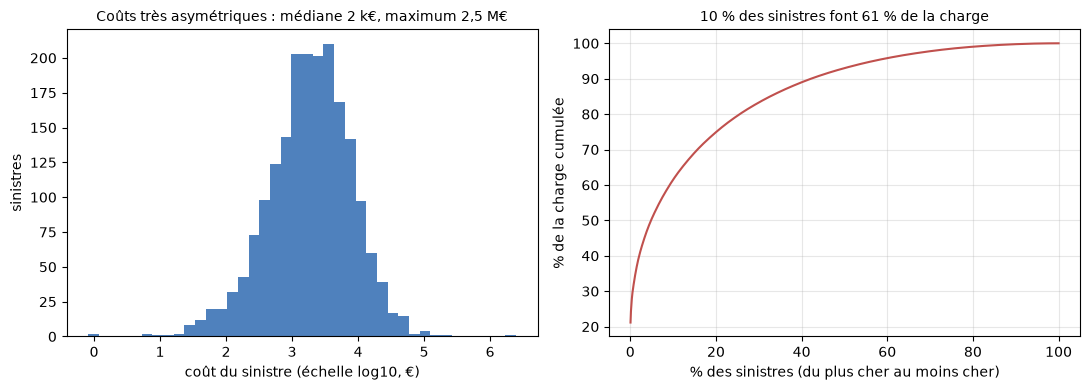

In [18]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4))
a1.hist(np.log10(z), bins=40, color="#4f81bd")
a1.set_xlabel("coût du sinistre (échelle log10, €)"); a1.set_ylabel("sinistres")
a1.set_title("Coûts très asymétriques : médiane 2 k€, maximum 2,5 M€")
cumul = z.cumsum() / z.sum()
a2.plot(100 * np.arange(1, len(z) + 1) / len(z), 100 * cumul, color="#c0504d")
a2.set_xlabel("% des sinistres (du plus cher au moins cher)"); a2.set_ylabel("% de la charge cumulée")
a2.set_title("10 % des sinistres font 61 % de la charge"); a2.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(FIGURES / "l3_queue_couts.png", dpi=150)

**Lecture.**
- **Distribution :** la médiane est de 1 997 € et la moyenne de 6 020 €, trois fois plus. Le 99ᵉ centile atteint 43 196 € et le maximum 2 475 975 €.
- **Concentration :**
  - les 2 dossiers les plus chers (0,1 %) font 23 % de la charge ;
  - les 1 % les plus chers en font 33 % ;
  - les 10 % les plus chers en font 61 %.
- **Les garanties les plus coûteuses** sont l'incendie (médiane 9 300 €) et la RC auto (3 885 €). Le bris de glace est très peu coûteux (médiane 294 €).

**Action :**
- Mettre en place un suivi des sinistres de plus de 50 000 €.
- Étudier une réassurance en excédent de sinistre. Un seul dossier a coûté 2,5 M€, soit 12 % des primes acquises de toute la période.